<a href="https://colab.research.google.com/github/Mayureshnema04/Test-file/blob/main/graph_rag_demo_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Knowledge Graphs & Graph RAG — a hands-on demo

A companion notebook for the class deck. Everything here is deliberately small: about
forty lines of real code, a ten-node graph and ten one-sentence documents. Run the cells
top to bottom.

**The story.** Nova Motors builds two cars, the EV-9 and the City-2. Dockworkers walk out
at the Port of Rotterdam. *Which car is affected?*

No single document in our corpus answers that. You have to connect four separate facts:

> strike → hits the Port of Rotterdam → which handles Acme Components → who supply the BU-7 brake unit → which is fitted to the EV-9

That is exactly the kind of question ordinary vector RAG answers badly and Graph RAG
answers well. We will build both and compare them on the same question.

**How to read this notebook.** Every code cell is preceded by a markdown cell stating
**what the code does**, **what goes in** and **what comes out** — so you can follow along
without reading the Python closely.

## Cell 1 — Setup

**What this code does:** Imports the three libraries we need — `networkx` for the graph, `matplotlib` to draw it, and (in the next cells) `sentence-transformers` to turn text into vectors. Uncomment the `pip` line the first time you run this.

**Input:** Nothing. This cell just prepares the environment.

**Output:** A confirmation line with the library versions. The first run may take a minute while the packages download.

NetworkX is the standard, open-source Python library used for creating, manipulating, and analyzing the structure, dynamics, and functions of complex networks (graphs)
. It provides highly flexible data structures to represent graphs along with a massive collection of built-in network algorithms

In [1]:
# !pip install networkx matplotlib scikit-learn sentence-transformers

import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

print("networkx  ", nx.__version__)
print("numpy     ", np.__version__)
print("Setup complete.")

networkx   3.7
numpy      2.4.6
Setup complete.


## Cell 2 — Our tiny document corpus

**What this code does:** Defines ten short documents — the kind of scattered sentences a real company has spread across contracts, tickets and news feeds. Read them and notice that **no single one** links the strike to a car. Documents 7 and 8 are deliberate distractors: they talk about Rotterdam without saying anything useful.

**Input:** Nothing — the documents are written by hand here.

**Output:** The ten documents, each with an index number.

In [2]:
DOCS = [
    "Acme Components ships all of its parts through the Port of Rotterdam.",
    "Delta Steel ships its output through the Port of Hamburg.",
    "Acme Components supplies the BU-7 brake unit.",
    "Delta Steel supplies the SF-3 steel frame.",
    "Every EV-9 leaving the Wolfsburg plant is fitted with a BU-7.",
    "Every City-2 leaving the Wolfsburg plant is fitted with an SF-3.",
    "Dockworkers began a strike at the Port of Rotterdam on 12 June.",
    "The Port of Rotterdam handled 14.5 million containers last year.",
    "An earlier strike at the Port of Rotterdam was settled in three days in 2019.",
    "Nova Motors reported record deliveries in the first quarter.",
]

for i, d in enumerate(DOCS):
    print(i, "|", d)

0 | Acme Components ships all of its parts through the Port of Rotterdam.
1 | Delta Steel ships its output through the Port of Hamburg.
2 | Acme Components supplies the BU-7 brake unit.
3 | Delta Steel supplies the SF-3 steel frame.
4 | Every EV-9 leaving the Wolfsburg plant is fitted with a BU-7.
5 | Every City-2 leaving the Wolfsburg plant is fitted with an SF-3.
6 | Dockworkers began a strike at the Port of Rotterdam on 12 June.
7 | The Port of Rotterdam handled 14.5 million containers last year.
8 | An earlier strike at the Port of Rotterdam was settled in three days in 2019.
9 | Nova Motors reported record deliveries in the first quarter.


## Cell 3 — Build the knowledge graph

**What this code does:** Turns those sentences into a graph. Each fact becomes a **triple** — *(subject, relationship, object)* — and each triple becomes one edge. In a production system an LLM reads the documents and extracts these automatically; here we write them out by hand so you can see exactly what a graph is made of. Note the direction: every edge points **downstream**, the way disruption actually travels.

**Input:** The nine triples listed in the code.

**Output:** The node and edge counts, then every edge with its relationship label.

Unlike a standard undirected graph (nx.Graph()), a DiGraph restricts edges to a specific direction (from a source node to a target node). It supports self-loops but prevents duplicate parallel edges between the same two nodes in the same direction

For pure LLM-based extraction: The LLM itself, with proper prompting (or fine-tuning), acts as the 'tool.' It's trained on vast amounts of text and can be instructed to output text in a triple format, or to identify entities and relationships. No external library directly performs this extraction step for the LLM.


while networkx is essential for what you do with the triples once they're found, the initial step of finding them from documents relies more on NLP techniques and the capabilities of the LLM itself, often supported by specialized NLP libraries.



In [3]:
TRIPLES = [
    ("Dock strike 12 June", "disrupts",  "Port of Rotterdam"),
    ("Port of Rotterdam",   "handles",   "Acme Components"),
    ("Port of Hamburg",     "handles",   "Delta Steel"),
    ("Acme Components",     "supplies",  "BU-7 brake unit"),
    ("Delta Steel",         "supplies",  "SF-3 steel frame"),
    ("BU-7 brake unit",     "fitted_to", "EV-9"),
    ("SF-3 steel frame",    "fitted_to", "City-2"),
    ("EV-9",                "made_by",   "Nova Motors"),
    ("City-2",              "made_by",   "Nova Motors"),
]

G = nx.DiGraph()
for subject, relation, obj in TRIPLES:
    G.add_edge(subject, obj, relation=relation)

print(f"The graph has {G.number_of_nodes()} nodes and {G.number_of_edges()} edges.\n")
for a, b, data in G.edges(data=True):
    print(f"  {a:20} --{data['relation']:10}--> {b}")

The graph has 10 nodes and 9 edges.

  Dock strike 12 June  --disrupts  --> Port of Rotterdam
  Port of Rotterdam    --handles   --> Acme Components
  Acme Components      --supplies  --> BU-7 brake unit
  Port of Hamburg      --handles   --> Delta Steel
  Delta Steel          --supplies  --> SF-3 steel frame
  BU-7 brake unit      --fitted_to --> EV-9
  SF-3 steel frame     --fitted_to --> City-2
  EV-9                 --made_by   --> Nova Motors
  City-2               --made_by   --> Nova Motors


## Cell 4 — Draw the graph

**What this code does:** Plots the graph so you can see the shape of the knowledge. The strike is orange and the two cars are dark blue. Trace with your finger from the strike down to a car — that is precisely what Graph RAG will do automatically in Cell 8.

**Input:** The graph `G` built in Cell 3.

**Output:** A picture of the ten nodes with their relationship labels on the edges. Notice the two parallel supply chains that only meet at Nova Motors.

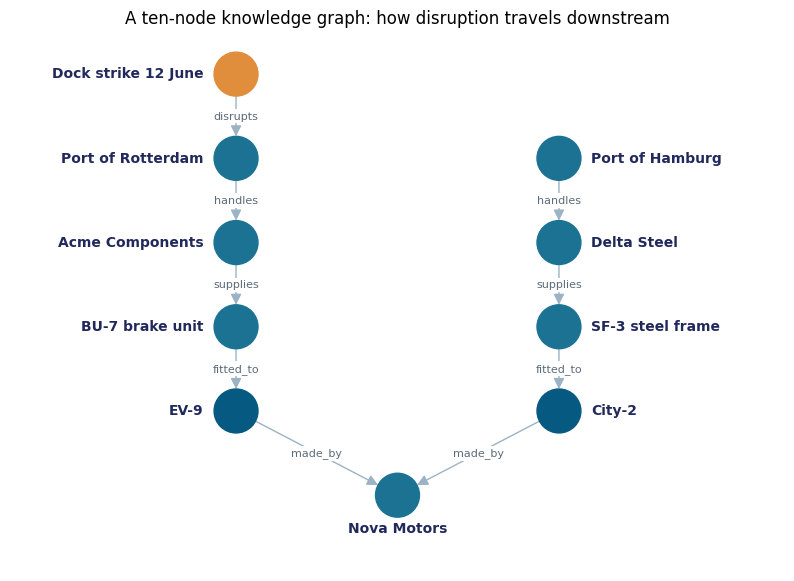

In [4]:
pos = {
    "Dock strike 12 June": (0.0,  3.0),
    "Port of Rotterdam":   (0.0,  2.0),
    "Acme Components":     (0.0,  1.0),
    "BU-7 brake unit":     (0.0,  0.0),
    "EV-9":                (0.0, -1.0),
    "Port of Hamburg":     (4.0,  2.0),
    "Delta Steel":         (4.0,  1.0),
    "SF-3 steel frame":    (4.0,  0.0),
    "City-2":              (4.0, -1.0),
    "Nova Motors":         (2.0, -2.0),
}

highlight = {"Dock strike 12 June": "#E08D3C", "EV-9": "#065A82", "City-2": "#065A82"}
colours = [highlight.get(n, "#1C7293") for n in G.nodes()]

plt.figure(figsize=(10, 7))
nx.draw_networkx_edges(G, pos, edge_color="#9BB3C4", arrowsize=16, node_size=1000)
nx.draw_networkx_nodes(G, pos, node_color=colours, node_size=1000)
nx.draw_networkx_edge_labels(G, pos, font_size=8, font_color="#5C6B7A", rotate=False,
                             bbox=dict(fc="white", ec="none", pad=1.5),
                             edge_labels={(a, b): d["relation"] for a, b, d in G.edges(data=True)})

for name, (x, y) in pos.items():                      # labels beside the dots, not inside
    if name == "Nova Motors":
        plt.text(x, y - 0.32, name, ha="center", va="top", fontsize=10,
                 fontweight="bold", color="#21295C")
    else:
        side = "right" if x == 0 else "left"
        plt.text(x + (-0.4 if x == 0 else 0.4), y, name, ha=side, va="center",
                 fontsize=10, fontweight="bold", color="#21295C")

plt.title("A ten-node knowledge graph: how disruption travels downstream", fontsize=12)
plt.xlim(-2.8, 6.8)
plt.ylim(-2.9, 3.5)
plt.axis("off")
plt.show()

### Programmatic Node Positioning

Instead of manually defining `pos`, `networkx` provides functions to automatically calculate node positions based on various algorithms. Here, we'll use `nx.spring_layout`.

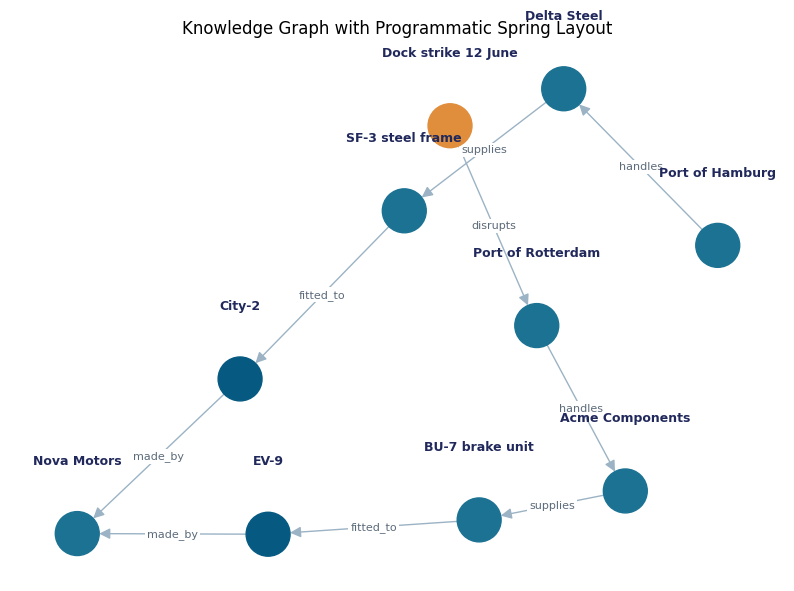

In [5]:
import networkx as nx
import matplotlib.pyplot as plt

# Calculate node positions using a spring layout algorithm
# You can experiment with different layout algorithms like nx.circular_layout, nx.spectral_layout, etc.
pos_spring = nx.spring_layout(G, k=0.5, iterations=50) # k is optimal distance between nodes, iterations for convergence

# Reuse highlight and colours from the previous drawing cell
highlight = {"Dock strike 12 June": "#E08D3C", "EV-9": "#065A82", "City-2": "#065A82"}
colours = [highlight.get(n, "#1C7293") for n in G.nodes()]

plt.figure(figsize=(10, 7))
nx.draw_networkx_edges(G, pos_spring, edge_color="#9BB3C4", arrowsize=16, node_size=1000)
nx.draw_networkx_nodes(G, pos_spring, node_color=colours, node_size=1000)
nx.draw_networkx_edge_labels(G, pos_spring, font_size=8, font_color="#5C6B7A", rotate=False,
                             bbox=dict(fc="white", ec="none", pad=1.5),
                             edge_labels={(a, b): d["relation"] for a, b, d in G.edges(data=True)})

# Adjust labels to be next to nodes, as automatic layouts don't usually have fixed coordinates for manual text placement
for name, (x, y) in pos_spring.items():
    plt.text(x, y + 0.15, name, ha="center", va="bottom", fontsize=9, fontweight="bold", color="#21295C")

plt.title("Knowledge Graph with Programmatic Spring Layout", fontsize=12)
plt.axis("off")
plt.show()

## Cell 5 — Turn text into vectors

**What this code does:** Loads a small embedding model that converts a sentence into a list of numbers, so sentences with similar meanings land close together. This is the engine behind ordinary vector RAG. The `try/except` adds a plain word-frequency fallback so the notebook still runs on a machine with no internet — the idea is identical, only the quality of the numbers differs.

**Input:** The ten documents from Cell 2.

**Output:** Which encoder was used, and the shape of the resulting matrix — one row per document, one column per dimension (384 with the real model, fewer with the fallback). *Note: the outputs saved in this file were produced with the fallback encoder, because the machine that built the notebook had no model download. With the real model the scores differ slightly; the conclusion in Cell 7 is the same.*

In [6]:
def build_encoder():
    try:
        from sentence_transformers import SentenceTransformer
        model = SentenceTransformer("all-MiniLM-L6-v2")
        return (lambda texts: np.asarray(model.encode(texts)),
                "sentence-transformers (all-MiniLM-L6-v2)")
    except Exception:
        from sklearn.feature_extraction.text import TfidfVectorizer
        vec = TfidfVectorizer().fit(DOCS)
        return (lambda texts: vec.transform(texts).toarray(),
                "offline fallback (TF-IDF word counts)")

encode, encoder_name = build_encoder()
doc_vectors = encode(DOCS)              # Not using any vector DB here for simplicity, dco_vector is list storking vectors

print("Encoder:", encoder_name)
print("Document matrix shape:", doc_vectors.shape, " (10 documents x embedding size)")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Encoder: sentence-transformers (all-MiniLM-L6-v2)
Document matrix shape: (10, 384)  (10 documents x embedding size)


## Cell 6 — Ask the question the vector-RAG way

**What this code does:** Embeds the question, measures cosine similarity against every document, and keeps the three closest — the classic *retrieve top-k chunks* step that sits behind almost every RAG system in production.

**Input:** The question string, plus `doc_vectors` from Cell 5.

**Output:** The three highest-scoring documents with their similarity scores. Read them carefully and ask yourself: could anyone answer the question from these three sentences?

In [7]:
QUESTION = "Which car is affected by the strike at the Port of Rotterdam?"

def cosine(a, B):               # custom vector seach fucntion
    a = a / (np.linalg.norm(a) + 1e-9)
    B = B / (np.linalg.norm(B, axis=1, keepdims=True) + 1e-9)
    return B @ a

scores = cosine(encode([QUESTION])[0], doc_vectors)           # not using imprted packages cosine similarity here, using code for simplicity.
top3 = np.argsort(-scores)[:3]

print("QUESTION:", QUESTION, "\n")
print("Top 3 chunks vector search would send to the LLM:\n")
for rank, i in enumerate(top3, 1):
    print(f"  {rank}. (score {scores[i]:.3f})  {DOCS[i]}")

vector_context = "\n".join(DOCS[i] for i in top3)

QUESTION: Which car is affected by the strike at the Port of Rotterdam? 

Top 3 chunks vector search would send to the LLM:

  1. (score 0.653)  An earlier strike at the Port of Rotterdam was settled in three days in 2019.
  2. (score 0.620)  Dockworkers began a strike at the Port of Rotterdam on 12 June.
  3. (score 0.510)  Acme Components ships all of its parts through the Port of Rotterdam.


## Cell 7 — Check whether that context is enough

**What this code does:** Tests one simple thing: do the retrieved chunks even mention a car? This is the weakness of vector RAG in a single line of code — the chunks look relevant because they share words with the question, but the chain of facts is broken, so the model has nothing to reason from.

**Input:** The `vector_context` string from Cell 6.

**Output:** A verdict on whether a car name appears in the retrieved text — and, when it does not, an explanation of why the retriever went wrong.

In [8]:
CARS = ["EV-9", "City-2"]
found = [c for c in CARS if c in vector_context]

print("Cars mentioned anywhere in the retrieved context:", found or "NONE")
print()
if len(found) != 1:
    print("The LLM cannot answer this reliably.")
    print("Every document that mentions Rotterdam scored highly, but the documents that")
    print("carry the actual chain - Acme -> BU-7 -> EV-9 - share no words with the")
    print("question, so they never made the top 3.")
else:
    print("Lucky retrieval this time - but nothing in the method guarantees it.")

Cars mentioned anywhere in the retrieved context: NONE

The LLM cannot answer this reliably.
Every document that mentions Rotterdam scored highly, but the documents that
carry the actual chain - Acme -> BU-7 -> EV-9 - share no words with the
question, so they never made the top 3.


## Cell 8 — Ask the same question the Graph-RAG way

**What this code does:** Finds the entity the question is about (the *anchor*), then walks outwards along the edges up to three hops and collects every triple it meets. That neighbourhood — not a pile of similar-looking text — becomes the context handed to the model.

**Input:** The question, and the graph `G` from Cell 3.

**Output:** The anchor node that was matched, and the small set of triples reachable from it. This time the chain is complete.

In [9]:
def find_anchor(question, graph):
    for node in graph.nodes():
        if node.lower() in question.lower():
            return node
    return None

def neighbourhood(graph, anchor, hops=3):
    near = nx.single_source_shortest_path_length(graph.to_undirected(), anchor, cutoff=hops)
    return [(a, d["relation"], b) for a, b, d in graph.edges(data=True)
            if a in near and b in near]

anchor = find_anchor(QUESTION, G)
graph_triples = neighbourhood(G, anchor, hops=3)

print("Anchor entity found in the question:", anchor, "\n")
print(f"Triples within 3 hops of it ({len(graph_triples)} of them):\n")
for a, r, b in graph_triples:
    print(f"  {a:20} --{r:10}--> {b}")

Anchor entity found in the question: Port of Rotterdam 

Triples within 3 hops of it (4 of them):

  Dock strike 12 June  --disrupts  --> Port of Rotterdam
  Port of Rotterdam    --handles   --> Acme Components
  Acme Components      --supplies  --> BU-7 brake unit
  BU-7 brake unit      --fitted_to --> EV-9


## Cell 9 — Show your working

**What this code does:** Asks the graph for the actual downstream path from the strike to each car. Because the edges point the way disruption travels, following them is a piece of real reasoning — and it is the part vector RAG cannot give you: a chain you can put in front of an auditor.

**Input:** The graph `G` and the two car names.

**Output:** For each car, either the exact path back to the strike, or a statement that no path exists — which is an equally useful answer, and one a vector search could never state with confidence.

In [10]:
STRIKE = "Dock strike 12 June"

for car in CARS:
    if nx.has_path(G, STRIKE, car):
        path = nx.shortest_path(G, STRIKE, car)
        print(f"{car:8} AFFECTED      " + "  ->  ".join(path))
    else:
        print(f"{car:8} not affected  (no downstream path from the strike)")

EV-9     AFFECTED      Dock strike 12 June  ->  Port of Rotterdam  ->  Acme Components  ->  BU-7 brake unit  ->  EV-9
City-2   not affected  (no downstream path from the strike)


## Cell 10 — The two prompts, side by side

**What this code does:** Assembles the prompt each method would actually send to a language model, so you can compare the raw material the model receives. The `ask_llm` helper at the bottom is commented out — drop in any LLM client and the same two contexts will produce two very different answers.

**Input:** `vector_context` from Cell 6 and `graph_triples` from Cell 8.

**Output:** Both prompts printed in full. Prompt B is shorter, structured, and actually contains the answer.

In [11]:
graph_context = "\n".join(f"{a} --{r}--> {b}" for a, r, b in graph_triples)

TEMPLATE = "Answer using only the context below.\n\nCONTEXT:\n{ctx}\n\nQUESTION: {q}"

print("=" * 70)
print("PROMPT A  -  VECTOR RAG")
print("=" * 70)
print(TEMPLATE.format(ctx=vector_context, q=QUESTION))

print("\n" + "=" * 70)
print("PROMPT B  -  GRAPH RAG")
print("=" * 70)
print(TEMPLATE.format(ctx=graph_context, q=QUESTION))

# To close the loop with a real model, install a client and uncomment:
#
# from openai import OpenAI
# client = OpenAI()
# def ask_llm(prompt):
#     r = client.chat.completions.create(model="gpt-4o-mini",
#                                        messages=[{"role": "user", "content": prompt}])
#     return r.choices[0].message.content
#
# print(ask_llm(TEMPLATE.format(ctx=graph_context, q=QUESTION)))

PROMPT A  -  VECTOR RAG
Answer using only the context below.

CONTEXT:
An earlier strike at the Port of Rotterdam was settled in three days in 2019.
Dockworkers began a strike at the Port of Rotterdam on 12 June.
Acme Components ships all of its parts through the Port of Rotterdam.

QUESTION: Which car is affected by the strike at the Port of Rotterdam?

PROMPT B  -  GRAPH RAG
Answer using only the context below.

CONTEXT:
Dock strike 12 June --disrupts--> Port of Rotterdam
Port of Rotterdam --handles--> Acme Components
Acme Components --supplies--> BU-7 brake unit
BU-7 brake unit --fitted_to--> EV-9

QUESTION: Which car is affected by the strike at the Port of Rotterdam?


## What just happened

| | Vector RAG | Graph RAG |
|---|---|---|
| What it retrieves | Text chunks that *look like* the question | The neighbourhood around the entities in the question |
| Our result | Three chunks about Rotterdam, no car named | `EV-9`, plus the path that proves it |
| Explainability | "It came from document 6" | The full chain, node by node |
| Cost | Cheap — embed the documents once | Extraction and graph building up front |

The language model was never the problem. **Retrieval was.**

## Five things to try

1. **Add a fact.** Append `("Port of Rotterdam", "handles", "Delta Steel")` to `TRIPLES`, re-run from Cell 3, and watch Cell 9 mark both cars as affected.
2. **Change the hop count.** Set `hops=2` in Cell 8 — the answer disappears, because the EV-9 sits three hops from the port. Set `hops=6` and irrelevant nodes creep in. Tuning this is most of the practical work in Graph RAG.
3. **Ask an easy question.** Try `"What does Acme Components supply?"` — a single-hop lookup where plain vector RAG does perfectly well. Knowing which questions actually need the graph is the real skill.
4. **Break the anchor.** Change the question to `"Which car is hit by the Rotterdam dock action?"` — `find_anchor` uses exact string matching and returns `None`. Real systems embed the entity names too, which is why most production stacks are hybrid: vectors find the entry point, the graph supplies the connections.
5. **Swap in your own domain.** Replace `DOCS` and `TRIPLES` with ten sentences and nine triples from your own work. If the graph gets you an answer the top-3 chunks miss, you have found a Graph RAG use case worth funding.